In [16]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from fat_tails import (
    get_degrees,
    plot_histogram,
    plot_loglog_histogram,
    plot_log_binned_histogram,
    plot_survival_function,
    alpha_regression,
    plot_alpha_regression,
    mle_alpha,
)

## 4.0

### 4.0.1-3 Import the data, draw their histogram. Correct the scale of the plot’s axes to double logarithmic. Apply logarithmic binning as well.

nodes: 1870
edges: 2277
min degree: 1
max degree: 56


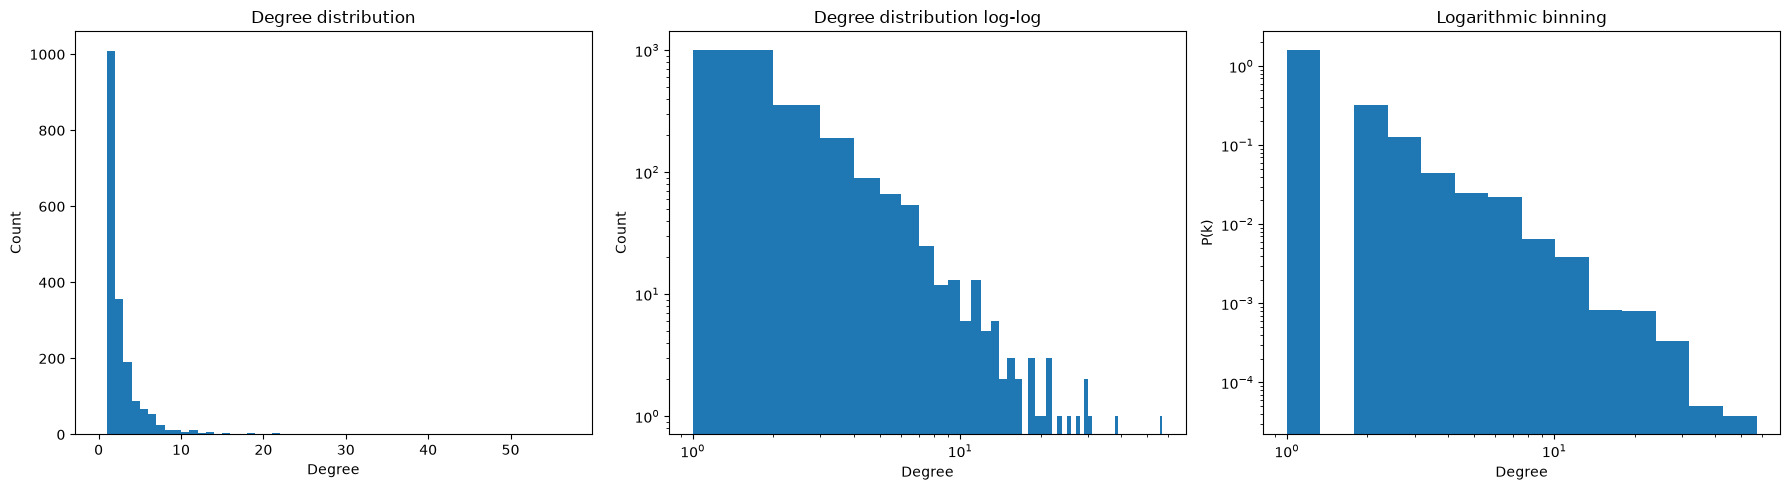

In [ ]:
edges = pd.read_csv("yeast.edges", sep = " ")
G = nx.from_pandas_edgelist(edges, "n1", "n2")
degrees = get_degrees(G)
print("nodes:", G.number_of_nodes())
print("edges:", G.number_of_edges())
print("min degree:", min(degrees))
print("max degree:", max(degrees))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_histogram(G, axes[0])
plot_loglog_histogram(G, axes[1])
plot_log_binned_histogram(G, ax=axes[2])
plt.tight_layout()
plt.show()

### 4.0.4 Compute and draw the survival function.

The survival function $S(k) = P(K \ge k) = 1 - P(K < k)$ is the fraction of nodes with degree at least $k$.
It starts at $S(1) = 1$ (every node has degree at least 1) and goes down as $k$ grows.
If $P(k) \sim k^{-\alpha}$, then $S(k) \sim k^{-(\alpha - 1)}$, so on log-log axes it is also a straight line, with slope $-(\alpha - 1)$.

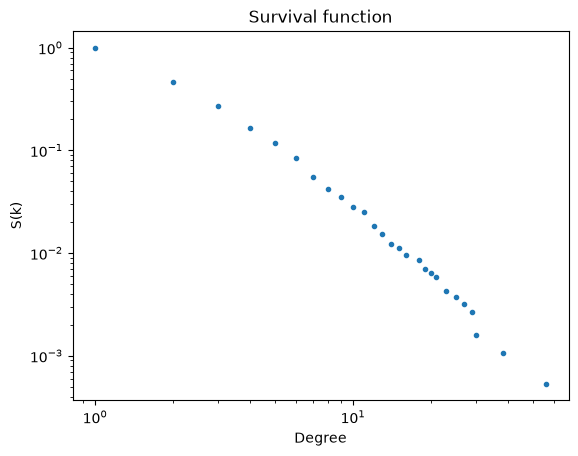

In [18]:
plot_survival_function(G)
plt.show()

### 4.0.5 Which chart is the most readable? Which is most robust for the noise?

- **Histogram** – the least readable. More than half of the nodes have degree 1, so almost everything is in the first few bars and the rest of the plot is empty.
- **Log-log histogram** – the beginning is clear, but above degree ~10 most degrees appear only 1–3 times or not at all. The bars jump up and down and leave gaps, so it is hard to see the trend.
- **Logarithmic binning** – the most readable. The bins get wider for larger degrees, so each bin collects enough nodes and the bars go down along a clear line. Downside: the result depends on the number of bins, and some narrow bins at small degrees can be empty, because degrees are whole numbers (the gap next to the first bar).
- **Survival function** – the most robust to noise. There are no bins, and each point counts all nodes with degree $\ge k$, so random ups and downs average out and the curve is smooth. 

### 4.0.6 Use the linear regression to the previous plots to determine the parameter α estimator.

On log-log axes a power law is a straight line: $\log P(k) = -\alpha \log k + c$.
We fit a line to each plot: for the two histograms $\alpha = -\text{slope}$, for the survival function $\alpha = 1 - \text{slope}$.
We use all degrees ($x_{min} = 1$), because for this network the plots look roughly straight from the start.

loglog: alpha = 2.11
log_binning: alpha = 2.80
survival: alpha = 2.98


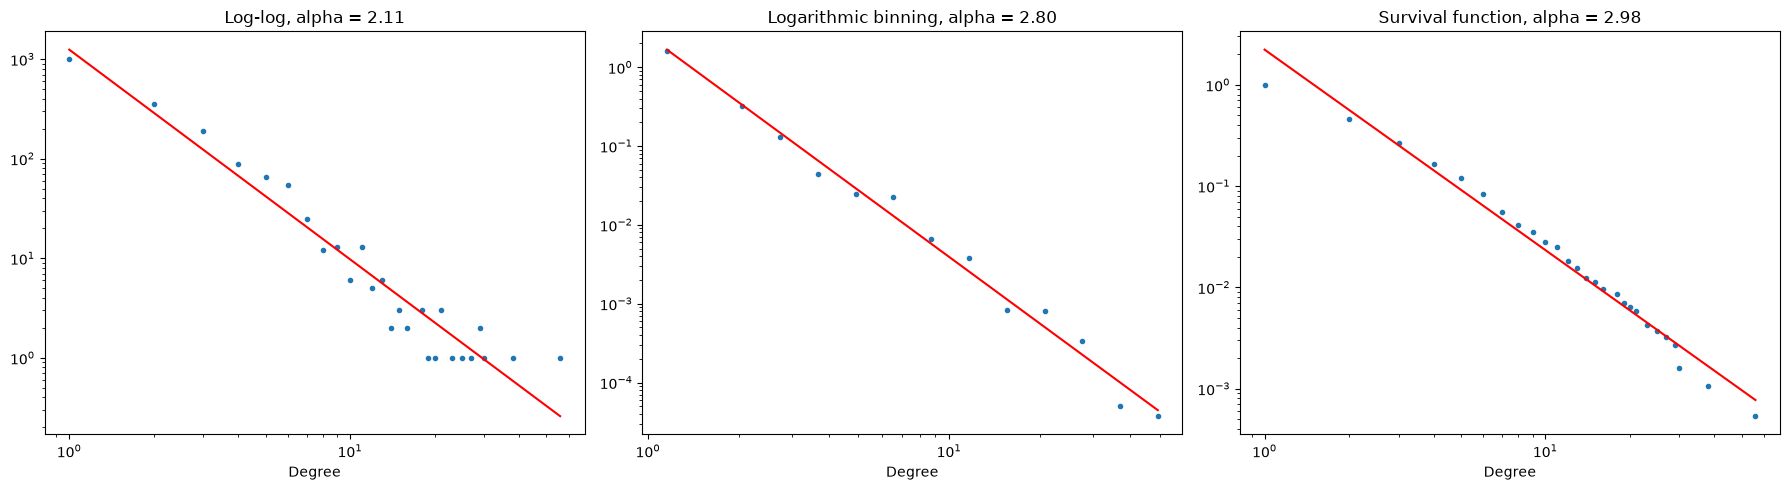

In [19]:
x_min = 1
for method, alpha in alpha_regression(G, x_min=x_min).items():
    print(f"{method}: alpha = {alpha:.2f}")

plot_alpha_regression(G, x_min=x_min)
plt.show()

### 4.0.7 Compute (formula and value for our data) MLE estimator for α with a known xmin.
$$\hat{\alpha} = 1 + n \left(\sum_{i=1}^{n} \ln\frac{x_i}{x_{min}}\right)^{-1}$$

In [20]:
mle_alpha(G, x_min=1)

np.float64(2.8177308179229126)

### 4.0.8 How will the result change if we do not know xmin?

The MLE formula needs $x_{min}$: only degrees $\ge x_{min}$ are used. If we don't know it, we have to choose it ourselves, and the result depends on that choice. Below we compute $\hat{\alpha}$ for different $x_{min}$.

x_min =  1: alpha = 2.82, nodes used = 1870
x_min =  2: alpha = 2.99, nodes used = 860
x_min =  3: alpha = 3.20, nodes used = 503
x_min =  4: alpha = 3.25, nodes used = 312
x_min =  5: alpha = 3.50, nodes used = 223
x_min =  6: alpha = 3.59, nodes used = 157
x_min =  7: alpha = 3.31, nodes used = 103
x_min =  8: alpha = 3.28, nodes used = 78
x_min =  9: alpha = 3.49, nodes used = 66
x_min = 10: alpha = 3.54, nodes used = 53
x_min = 11: alpha = 3.86, nodes used = 47
x_min = 12: alpha = 3.52, nodes used = 34
x_min = 13: alpha = 3.60, nodes used = 29
x_min = 14: alpha = 3.44, nodes used = 23
x_min = 15: alpha = 3.63, nodes used = 21
x_min = 16: alpha = 3.63, nodes used = 18
x_min = 17: alpha = 3.73, nodes used = 16
x_min = 18: alpha = 4.23, nodes used = 16
x_min = 19: alpha = 4.06, nodes used = 13
x_min = 20: alpha = 4.31, nodes used = 12


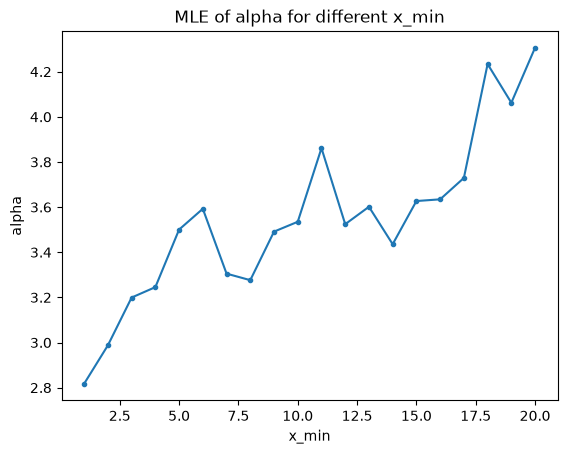

In [21]:
x_mins = range(1, 21)
alphas = [mle_alpha(G, x) for x in x_mins]
tail_sizes = [sum(degrees >= x) for x in x_mins]

for x, alpha, n in zip(x_mins, alphas, tail_sizes):
    print(f"x_min = {x:2d}: alpha = {alpha:.2f}, nodes used = {n}")

plt.plot(x_mins, alphas, marker=".")
plt.xlabel("x_min")
plt.ylabel("alpha")
plt.title("MLE of alpha for different x_min")
plt.show()

The estimate grows with $x_{min}$: from ≈2.82 for $x_{min} = 1$ (all 1870 nodes) to ≈3.3–3.6 for $x_{min}$ between 5 and 10 (223 to 53 nodes). Above that it jumps between ≈3.4 and ≈4.3, because only a few dozen nodes are left.

- **Too small $x_{min}$** – many nodes, so the estimate is stable, but it also uses small degrees, which do not follow the power law exactly (the survival function bends a little at the start). This gives a smaller α.
- **Too large $x_{min}$** – only a few nodes are left, so the estimate is noisy.

So without a known $x_{min}$, α is less certain: it depends on our choice of $x_{min}$. A reasonable choice is where the survival function becomes a straight line and α stops changing much, here $x_{min} \approx 5$–$10$, which gives $\alpha \approx 3.3$–$3.5$.